# H2 — Is a natural image fitted faster than noise?

**Hypothesis.** The same untrained U-Net fits a natural image much faster than the same pixels shuffled (same colours, no structure) or uniform noise.

**Measurement.** Training MSE against the target. Fitting speed = iterations until MSE < 0.01, plus MSE at iteration 500. No noise is added and no pixels are held out.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage import io

from dip.analysis import (IMAGES, INK, MODEL_COLORS, MODEL_LABELS, MUTED, PALETTE,
                          load_runs, noisy_baseline, savefig, setup_style, summarize)
from dip.utils import DATA_DIR, RESULTS_DIR, add_gaussian_noise, load_image, to_numpy_image

setup_style()
pd.set_option("display.precision", 2)

In [2]:
h2 = load_runs("h2")
TARGET_LABEL = {"clean": "natural image", "shuffled": "shuffled pixels", "noise": "uniform noise"}
TARGET_COLOR = {"clean": PALETTE[0], "shuffled": PALETTE[1], "noise": PALETTE[2]}
THRESH = 0.01

def speed(g):
    hit = g.loc[g["loss"] < THRESH, "iter"]
    return pd.Series({
        "iters_to_mse<0.01": int(hit.iloc[0]) if len(hit) else np.nan,
        "mse@500": g.loc[g["iter"] == 500, "loss"].item(),
        "final_mse": g["loss"].iloc[-1],
        "final_psnr_vs_target": g["psnr_clean"].iloc[-1],
    })
table = h2.groupby(["image", "target"]).apply(speed, include_groups=False).reset_index()
table  # NaN = threshold never reached within 3000 iterations

,image,target,iters_to_mse<0.01,mse@500,final_mse,final_psnr_vs_target
0,kodim03,clean,20.0,9.26e-04,2.35e-04,36.29
1,kodim03,noise,NaN,4.55e-02,2.92e-02,15.35
2,kodim03,shuffled,NaN,2.48e-02,1.20e-02,19.19
3,kodim13,clean,130.0,5.32e-03,1.55e-03,28.09
4,kodim13,noise,NaN,4.56e-02,2.95e-02,15.30
5,kodim13,shuffled,2700.0,3.58e-02,8.76e-03,20.58


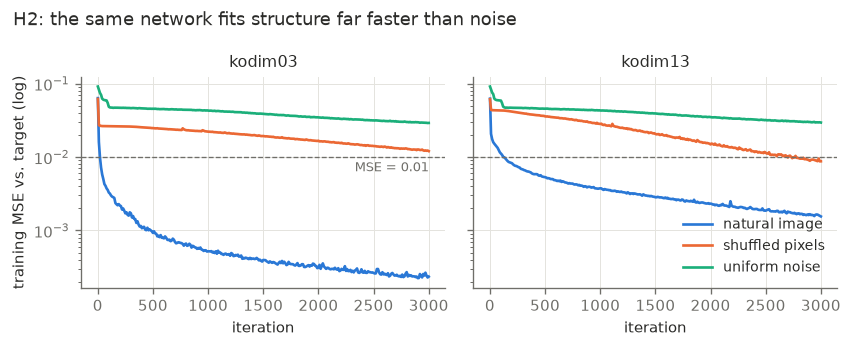

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.9), sharey=True)
for ax, im in zip(axes, ["kodim03", "kodim13"]):
    for t in ["clean", "shuffled", "noise"]:
        g = h2[(h2.image == im) & (h2.target == t)]
        ax.plot(g["iter"], g["loss"], color=TARGET_COLOR[t], label=TARGET_LABEL[t])
    ax.axhline(THRESH, color=MUTED, lw=0.8, ls="--")
    ax.set_yscale("log")
    ax.set_title(im)
    ax.set_xlabel("iteration")
axes[0].set_ylabel("training MSE vs. target (log)")
axes[0].text(3000, THRESH * 0.88, "MSE = 0.01", color=MUTED, ha="right", va="top", fontsize=8)
axes[1].legend(loc="lower right")
fig.suptitle("H2: the same network fits structure far faster than noise", x=0.02, ha="left")
fig.tight_layout()
savefig(fig, "h2_fitting_speed")

## Findings

- **H2 is confirmed** (this reproduces Fig. 2 of Ulyanov et al., 2018).
- The natural image drops below MSE 0.01 after 20 (`kodim03`) and 130 (`kodim13`) iterations. Shuffled pixels reach it only after 2700 iterations (`kodim13`) or not at all (`kodim03`). Uniform noise never reaches it within 3000 iterations.
- After 3000 iterations, the fit is 36.5 dB (`kodim03`) / 28.1 dB (`kodim13`) for the natural images, compared with about 19–21 dB for shuffled pixels and about 15 dB for noise.
- **Shuffling destroys the speed-up** even though the colours are identical. So the speed comes from spatial structure, not from colour statistics.
- The textured `kodim13` is fitted more slowly than `kodim03`, consistent with H1: fine texture is "late" content.